# 01 EDA

O que preciso de saber dos dados antes de modelar. Uso só 2013-2019: o 2020 fica de fora de tudo, porque é o test set final.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, VERM = "#0072B2", "#D55E00"          # paleta Okabe-Ito, legível por daltónicos
plt.rcParams.update({
    "font.size": 8, "axes.titlesize": 8.5, "axes.titleweight": "normal", "axes.titlelocation": "left",
    "figure.figsize": (3.4, 2.6), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.unicode_minus": False, "savefig.dpi": 200,
    "savefig.bbox": "tight", "legend.frameon": False,
})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def guardar(fig, nome):
    fig.savefig(FIG / f"{nome}.png")
    plt.show()

## Dados

In [2]:
raw = pd.read_csv("../data/classification_task1_train.csv", parse_dates=["Date"])
df = raw[raw["Year"] < 2020].copy()          # 2020 fica de fora: é o test set final
df["mes"] = df["Date"].dt.month
print(f"{len(df)} linhas, {df['Date'].nunique()} datas, {df['HAB'].sum()} eventos HAB ({df['HAB'].mean():.1%})")
print(f"{df['CHL'].notna().sum()} linhas têm CHL e incerteza")

905 linhas, 605 datas, 107 eventos HAB (11.8%)
476 linhas têm CHL e incerteza


Aqui uso as 905 linhas, com e sem CHL. Os modelos só vão usar as 476 completas, e o notebook 02 explica porquê.

## 1. Quantos dados há por ano?

In [3]:
por_ano = df.groupby("Year").agg(linhas=("HAB", "size"), datas=("Date", "nunique"), eventos=("HAB", "sum"))
por_ano["taxa HAB (%)"] = (100 * por_ano["eventos"] / por_ano["linhas"]).round(1)
por_ano

,linhas,datas,eventos,taxa HAB (%)
Year,,,,
2013,112,85,10,8.9
2014,84,69,0,0.0
2015,57,48,27,47.4
2016,153,98,19,12.4
2017,174,111,0,0.0
2018,162,98,22,13.6
2019,163,96,29,17.8


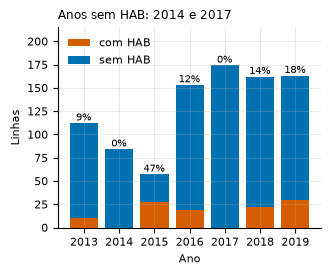

In [4]:
sem_hab = por_ano.index[por_ano["eventos"] == 0]
fig, ax = plt.subplots()
ax.bar(por_ano.index, por_ano["eventos"], color=VERM, label="com HAB")
ax.bar(por_ano.index, por_ano["linhas"] - por_ano["eventos"], bottom=por_ano["eventos"], color=AZUL, label="sem HAB")
for ano, taxa in por_ano["taxa HAB (%)"].items():
    ax.text(ano, por_ano.loc[ano, "linhas"] + 3, f"{taxa:.0f}%", ha="center", fontsize=7)
ax.set(xlabel="Ano", ylabel="Linhas", ylim=(0, 215), xticks=por_ano.index, title=f"Anos sem HAB: {' e '.join(map(str, sem_hab))}")
ax.legend(loc="upper left"); guardar(fig, "01_linhas_por_ano")

In [5]:
print("datas por nº de linhas (clusters medidos nesse dia):", df.groupby("Date").size().value_counts().sort_index().to_dict())

datas por nº de linhas (clusters medidos nesse dia): {1: 305, 2: 300}


Os anos 2014 e 2017 não têm nenhum HAB, por isso não dão AUC como ano de validação: com uma só classe o AUC não existe. Continuam a servir para treinar. A taxa muda muito entre os outros anos, de 8.9% em 2013 a 47.4% em 2015.

Cada data tem 1 ou 2 clusters medidos (305 datas com 1, 300 com 2). Linhas da mesma data parecem-se, por isso nunca as separo entre training e validation.

Decisão: leave-one-year-out cross-validation, com o ano inteiro de fora em cada fold, e reporto o AUC de cada ano e não só a média.

## 2. Em que meses há HAB?

In [6]:
mes = df.groupby("mes")["HAB"].agg(eventos="sum", linhas="size")
mes["taxa HAB (%)"] = 100 * mes["eventos"] / mes["linhas"]
mes.round(1).T

mes,1,2,3,4,5,6,7,8,9,10,11,12
eventos,2.0,3.0,4.0,7.0,10.0,22.0,16.0,23.0,11.0,6.0,1.0,2.0
linhas,68.0,68.0,76.0,85.0,81.0,60.0,82.0,93.0,83.0,79.0,66.0,64.0
taxa HAB (%),2.9,4.4,5.3,8.2,12.3,36.7,19.5,24.7,13.3,7.6,1.5,3.1


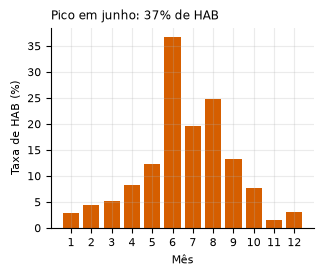

In [7]:
NOMES = ["janeiro", "fevereiro", "março", "abril", "maio", "junho", "julho", "agosto", "setembro", "outubro", "novembro", "dezembro"]
pico = mes["taxa HAB (%)"].idxmax()
fig, ax = plt.subplots()
ax.bar(mes.index, mes["taxa HAB (%)"], color=VERM)
ax.set(xlabel="Mês", ylabel="Taxa de HAB (%)", xticks=range(1, 13),
       title=f"Pico em {NOMES[pico - 1]}: {mes.loc[pico, 'taxa HAB (%)']:.0f}% de HAB")
guardar(fig, "02_hab_por_mes")

O HAB concentra-se no verão: 36.7% das linhas de junho, 24.7% de agosto e 19.5% de julho, contra menos de 6% de novembro a março.

Decisão: o dia do ano entra como feature. No notebook 02 vejo como o codificar.

## 3. E por cluster?

In [8]:
cl = df.groupby("spatial_cluster")["HAB"].agg(linhas="size", eventos="sum")
cl["taxa HAB (%)"] = (100 * cl["eventos"] / cl["linhas"]).round(1)
cl

,linhas,eventos,taxa HAB (%)
spatial_cluster,,,
0,422,25,5.9
1,11,0,0.0
2,48,16,33.3
3,2,0,0.0
4,264,54,20.5
5,158,12,7.6


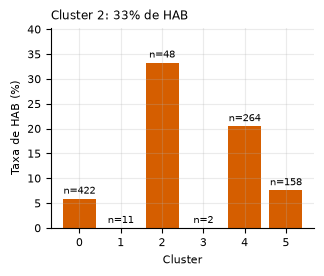

In [9]:
topo = cl["taxa HAB (%)"].idxmax()
fig, ax = plt.subplots()
ax.bar(cl.index, cl["taxa HAB (%)"], color=VERM)
for c, r in cl.iterrows():
    ax.text(c, r["taxa HAB (%)"] + 1, f"n={int(r['linhas'])}", ha="center", fontsize=7)
ax.set(xlabel="Cluster", ylabel="Taxa de HAB (%)", ylim=(0, cl["taxa HAB (%)"].max() + 7),
       title=f"Cluster {topo}: {cl.loc[topo, 'taxa HAB (%)']:.0f}% de HAB")
guardar(fig, "03_hab_por_cluster")

O cluster 2 tem a taxa mais alta (16 eventos em 48 linhas, 33.3%), seguido do 4 (20.5%). Os clusters 0 e 5 ficam abaixo de 8%. Os clusters 1 e 3 têm 11 e 2 linhas e nenhum HAB.

Decisão: o cluster entra como feature, em one-hot. Com tão poucas linhas nos clusters 1 e 3 o modelo não aprende nada sobre eles. O que o `predict` faz com um cluster raro ou novo fica para o notebook 02.

## 4. As variáveis mudam quando há HAB?

A mediana de cada variável com e sem HAB. O CHL e a incerteza só existem nas linhas completas.

In [10]:
variaveis = ["SST", "UI", "CHL", "CHL_uncertainty"]
tab = {v: {"linhas": df[v].notna().sum(), "mediana com HAB": df.loc[df.HAB == 1, v].median(),
           "mediana sem HAB": df.loc[df.HAB == 0, v].median()} for v in variaveis}
pd.DataFrame(tab).T.round(2)

,linhas,mediana com HAB,mediana sem HAB
SST,905.0,15.18,14.34
UI,905.0,0.03,0.04
CHL,476.0,4.83,2.77
CHL_uncertainty,476.0,37.78,32.20


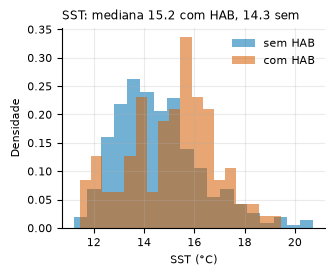

In [11]:
def comparar(col, curto, nome_x, ficheiro, dec, log=False, n_bins=18):
    x = df[[col, "HAB"]].dropna()
    bins = np.logspace(np.log10(x[col].min()), np.log10(x[col].max()), n_bins + 1) if log else n_bins
    fig, ax = plt.subplots()
    for h, cor, rot in [(0, AZUL, "sem HAB"), (1, VERM, "com HAB")]:
        ax.hist(x.loc[x.HAB == h, col], bins=bins, density=True, alpha=0.55, color=cor, label=rot)
    m1, m0 = x.loc[x.HAB == 1, col].median(), x.loc[x.HAB == 0, col].median()
    if log: ax.set_xscale("log")
    ax.set(xlabel=nome_x, ylabel="Densidade", title=f"{curto}: mediana {m1:.{dec}f} com HAB, {m0:.{dec}f} sem")
    ax.legend(); guardar(fig, ficheiro)

comparar("SST", "SST", "SST (°C)", "04_sst", 1)

A água está mais quente com HAB: mediana 15.2 °C contra 14.3 °C. A UI quase não muda (medianas de 0.03 e 0.04), mas não a retiro já: pode ajudar em combinação com as outras, e o notebook 02 mede isso.

CHL: mínimo 0.35, mediana 2.98, máximo 62.7 mg/m³


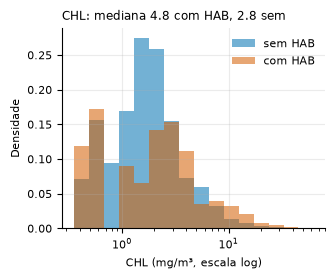

In [12]:
cc = df.dropna(subset=["CHL"])
print(f"CHL: mínimo {cc['CHL'].min():.2f}, mediana {cc['CHL'].median():.2f}, máximo {cc['CHL'].max():.1f} mg/m³")
comparar("CHL", "CHL", "CHL (mg/m³, escala log)", "05_chl", 1, log=True, n_bins=16)

O CHL tem muitos valores baixos e poucos muito altos: vai de 0.35 a 62.7 mg/m³, com mediana 2.98. Com HAB a mediana é 4.8 contra 2.8.

Decisão: uso log(CHL) nos modelos lineares. O notebook 02 mede quanto isso conta.

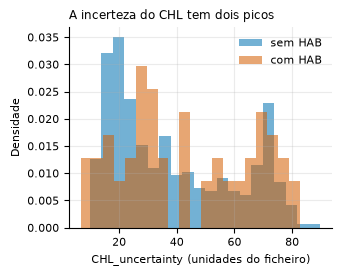

In [13]:
fig, ax = plt.subplots()
for h, cor, rot in [(0, AZUL, "sem HAB"), (1, VERM, "com HAB")]:
    ax.hist(cc.loc[cc.HAB == h, "CHL_uncertainty"], bins=20, density=True, alpha=0.55, color=cor, label=rot)
ax.set(xlabel="CHL_uncertainty (unidades do ficheiro)", ylabel="Densidade", title="A incerteza do CHL tem dois picos")
ax.legend(); guardar(fig, "06_incerteza")

A incerteza do CHL tem dois picos, um perto de 20 e outro perto de 70, e a distribuição é parecida com e sem HAB.

Decisão: entra como feature contínua, sem cortes. O notebook 02 mede o que acrescenta.